# Credit Default Prediction, DSC LOGIKA UI 2026

The task is to rank loan applications by the risk of reaching 90 DPD within 12 months, scored with KS.

Approach in short:

1. Build customer level features from six tables, using only records available at the decision time.
2. Train gradient boosted trees (LightGBM, CatBoost, XGBoost) on two feature sets and a spline logistic regression.
3. Blend the models by rank, since KS only depends on the ordering of scores.

Everything runs on CPU with fixed seeds so the submission can be reproduced exactly.

In [1]:
import os, random, joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from scipy.stats import ks_2samp, rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer, SplineTransformer

SEED = 13
VARIANT = "main"
N_FOLDS = 10
TREE_SEEDS = 1
LR = 0.01
random.seed(SEED)
np.random.seed(SEED)
KAGGLE = "/kaggle/input/data-science-competition-logika-ui-2026/"
D = KAGGLE if os.path.exists(KAGGLE) else "data/"
os.makedirs("models", exist_ok=True)
os.makedirs("variants", exist_ok=True)

## Features

Every table is joined to the selected application through `customer_id` and filtered against `decision_datetime`.
The applications table gives loan terms, and the profile table gives declared income used for affordability ratios.
Default rates move with the calendar, from 12 percent for May decisions to 15 percent for February, so the decision day of year is kept as a feature.

In [2]:
def load_apps():
    dt = ["application_datetime", "decision_datetime"]
    tr = pd.read_csv(D + "train_applications.csv", parse_dates=dt)
    te = pd.read_csv(D + "test_applications.csv", parse_dates=dt)
    return pd.concat([tr, te], ignore_index=True)


def app_features(app):
    f = app[["application_id", "customer_id", "decision_datetime"]].copy()
    f["loan_amount"] = app.loan_amount
    f["interest_rate"] = app.annual_interest_rate
    f["installment"] = app.proposed_monthly_installment
    f["loan_purpose"] = app.loan_purpose.astype("category")
    f["decision_lag_h"] = (app.decision_datetime - app.application_datetime).dt.total_seconds() / 3600
    f["app_hour"] = app.application_datetime.dt.hour
    f["app_dow"] = app.application_datetime.dt.dayofweek
    # default rates move with the season (12% in May, 15% in February), so the decision date enters as day of year
    f["dec_doy"] = app.decision_datetime.dt.dayofyear
    return f


def profile_features(f):
    cp = pd.read_csv(D + "customer_profiles.csv")
    for c in ["region", "employment_type", "housing_status"]:
        cp[c] = cp[c].astype("category")
    f = f.merge(cp, on="customer_id", how="left")
    inc = f.declared_monthly_income
    f["inst_to_income"] = f.installment / inc
    f["loan_to_income"] = f.loan_amount / inc
    f["income_per_dependent"] = inc / (f.dependents + 1)
    f["tenure_to_age"] = f.employment_tenure_months / (f.age * 12)
    return f

Bureau reports from every provider and every past application are noisy readings of the same customer, so besides the current reports we also pool all of them.

In [3]:
def bureau_features(app):
    bu = pd.read_csv(D + "bureau_observations.csv", parse_dates=["report_datetime", "available_datetime"])
    bu = bu.merge(app[["customer_id", "application_id", "decision_datetime"]], on="customer_id", suffixes=("", "_sel"))
    bu["age_days"] = (bu.decision_datetime - bu.report_datetime).dt.total_seconds() / 86400
    bu["unscored"] = bu.score.isna().astype(int)
    bu["revolving_free"] = bu.revolving_credit_limit - bu.revolving_outstanding_balance

    cur = bu[bu.application_id == bu.application_id_sel]
    g = cur.groupby("application_id_sel")
    out = g.agg(
        bu_score_mean=("score", "mean"), bu_score_min=("score", "min"), bu_score_max=("score", "max"),
        bu_score_std=("score", "std"), bu_unscored=("unscored", "sum"), bu_reports=("score", "size"),
        bu_active_max=("active_accounts", "max"), bu_active_mean=("active_accounts", "mean"),
        bu_outstanding_max=("outstanding_balance", "max"), bu_outstanding_mean=("outstanding_balance", "mean"),
        bu_rev_limit_max=("revolving_credit_limit", "max"), bu_rev_bal_max=("revolving_outstanding_balance", "max"),
        bu_util_max=("utilization", "max"), bu_util_mean=("utilization", "mean"),
        bu_inq_max=("inquiries_last_6m", "max"), bu_inq_mean=("inquiries_last_6m", "mean"),
        bu_delinq_max=("delinquent_accounts_last_12m", "max"), bu_delinq_sum=("delinquent_accounts_last_12m", "sum"),
        bu_age_min=("age_days", "min"), bu_age_max=("age_days", "max"),
    )
    # the freshest report is the best snapshot of the customer at decision time
    latest = cur.sort_values("report_datetime").groupby("application_id_sel").last()
    for c in ["score", "outstanding_balance", "utilization", "inquiries_last_6m", "delinquent_accounts_last_12m", "active_accounts"]:
        out["bu_latest_" + c] = latest[c]
    piv = cur.pivot_table(index="application_id_sel", columns="bureau_provider", values="score")
    out = out.join(piv.add_prefix("bu_score_"))

    hist = bu[bu.application_id != bu.application_id_sel]
    h = hist.groupby("application_id_sel").agg(
        buh_score_mean=("score", "mean"), buh_score_min=("score", "min"),
        buh_delinq_max=("delinquent_accounts_last_12m", "max"), buh_outstanding_max=("outstanding_balance", "max"),
        buh_inq_max=("inquiries_last_6m", "max"), buh_n=("score", "size"),
    )
    hl = hist.sort_values("report_datetime").groupby("application_id_sel").last()
    h["buh_last_score"] = hl.score
    h["buh_last_age_days"] = hl.age_days
    out = out.join(h)
    out["bu_score_trend"] = out.bu_score_mean - out.buh_score_mean
    out["bu_score_trend_last"] = out.bu_latest_score - out.buh_last_score
    # every report is a noisy reading of the same customer, so pooling all of them reduces noise
    pool = ["score", "utilization", "inquiries_last_6m", "delinquent_accounts_last_12m", "outstanding_balance",
            "revolving_outstanding_balance", "active_accounts"]
    out = out.join(bu.groupby("application_id_sel")[pool].mean().add_prefix("bua_"))
    out["bua_score_median"] = bu.groupby("application_id_sel").score.median()
    out["bua_unscored_rate"] = bu.groupby("application_id_sel").unscored.mean()
    return out.rename_axis("application_id").reset_index()

In [4]:
def previous_features(app):
    pa = pd.read_csv(D + "previous_applications.csv", parse_dates=["application_datetime", "decision_datetime"])
    pa = pa.merge(app[["customer_id", "decision_datetime"]].rename(columns={"decision_datetime": "cut"}), on="customer_id")
    pa["days_ago"] = (pa.cut - pa.decision_datetime).dt.total_seconds() / 86400
    pa["approved"] = (pa.decision == "approved").astype(int)
    pa["rejected"] = (pa.decision == "rejected").astype(int)
    pa["cancelled"] = (pa.decision == "cancelled").astype(int)
    # months elapsed since origination tells whether the loan is still being repaid
    pa["months_elapsed"] = pa.days_ago / 30.44
    pa["active"] = (pa.approved == 1) & (pa.months_elapsed < pa.term_months)
    pa["active_inst"] = np.where(pa.active, pa.scheduled_monthly_installment, 0)
    pa["remaining_principal"] = np.where(
        pa.active, pa.approved_amount * (1 - pa.months_elapsed / pa.term_months), 0)
    for w in [90, 180, 365]:
        pa[f"in{w}"] = (pa.days_ago <= w).astype(int)
        pa[f"rej{w}"] = pa.rejected * pa[f"in{w}"]

    g = pa.groupby("customer_id")
    out = g.agg(
        pa_n=("decision", "size"), pa_approved=("approved", "sum"), pa_rejected=("rejected", "sum"),
        pa_cancelled=("cancelled", "sum"), pa_req_mean=("requested_amount", "mean"),
        pa_req_max=("requested_amount", "max"), pa_appr_sum=("approved_amount", "sum"),
        pa_rate_mean=("annual_interest_rate", "mean"), pa_rate_max=("annual_interest_rate", "max"),
        pa_term_mean=("term_months", "mean"), pa_last_days=("days_ago", "min"), pa_first_days=("days_ago", "max"),
        pa_active_n=("active", "sum"), pa_active_inst=("active_inst", "sum"),
        pa_remaining=("remaining_principal", "sum"),
        pa_in90=("in90", "sum"), pa_in180=("in180", "sum"), pa_in365=("in365", "sum"),
        pa_rej90=("rej90", "sum"), pa_rej365=("rej365", "sum"),
    )
    out["pa_reject_rate"] = out.pa_rejected / out.pa_n
    return out.reset_index()

Repayment history is the strongest source. A late rate is only fair when it counts installments that had enough time to become late, so each DPD threshold uses matured installments only.

In [5]:
def repayment_features(app):
    rh = pd.read_csv(D + "repayment_history.csv", parse_dates=["due_date", "last_payment_datetime"])
    rh = rh.merge(app[["customer_id", "decision_datetime"]].rename(columns={"decision_datetime": "cut"}), on="customer_id")
    rh["days_ago"] = (rh.cut - rh.due_date).dt.total_seconds() / 86400
    rh["unpaid"] = rh.amount_due - rh.amount_paid
    rh["paid_ratio"] = rh.amount_paid / rh.amount_due
    rh["pay_delay"] = (rh.last_payment_datetime - rh.due_date).dt.total_seconds() / 86400
    rh["late"] = (rh.max_days_past_due > 0).astype(int)
    rh["late30"] = (rh.max_days_past_due >= 30).astype(int)
    rh["late90"] = (rh.max_days_past_due >= 90).astype(int)
    rh["open_dpd"] = (rh.days_past_due > 0).astype(int)
    rh["recent"] = rh.days_ago <= 180
    for w in [90, 365]:
        rh[f"late_{w}"] = rh.late.where(rh.days_ago <= w)
        rh[f"dpd_{w}"] = rh.max_days_past_due.where(rh.days_ago <= w)
    for c in ["max_days_past_due", "late", "late30", "paid_ratio", "pay_delay"]:
        rh["r_" + c] = rh[c].where(rh.recent)
    # an installment due t days ago cannot show more than t days past due, so each rate only counts matured ones
    thresholds = [1, 15, 30, 60, 90]
    for t in thresholds:
        rh[f"mat{t}"] = (rh.days_ago >= t).astype(int)
        rh[f"hit{t}"] = ((rh.max_days_past_due >= t) & (rh.days_ago >= t)).astype(int)
    rh["sev"] = rh.max_days_past_due.where(rh.late == 1)
    rh["loan_seq"] = rh.groupby(["customer_id", "loan_id"]).due_date.rank()

    g = rh.groupby("customer_id")
    out = g.agg(
        rh_n=("amount_due", "size"), rh_loans=("loan_id", "nunique"),
        rh_dpd_now_max=("days_past_due", "max"), rh_dpd_now_sum=("days_past_due", "sum"),
        rh_open_dpd=("open_dpd", "sum"), rh_maxdpd_max=("max_days_past_due", "max"),
        rh_maxdpd_mean=("max_days_past_due", "mean"), rh_late=("late", "mean"), rh_late_n=("late", "sum"),
        rh_late30=("late30", "sum"), rh_late90=("late90", "sum"), rh_unpaid=("unpaid", "sum"),
        rh_paid_ratio=("paid_ratio", "mean"), rh_paid_ratio_min=("paid_ratio", "min"),
        rh_delay_mean=("pay_delay", "mean"), rh_delay_max=("pay_delay", "max"),
        rh_r_maxdpd=("r_max_days_past_due", "max"), rh_r_late=("r_late", "mean"),
        rh_r_late30=("r_late30", "sum"), rh_r_paid_ratio=("r_paid_ratio", "mean"),
        rh_r_delay=("r_pay_delay", "mean"), rh_last_due_days=("days_ago", "min"),
        rh_late_90=("late_90", "mean"), rh_late_365=("late_365", "mean"),
        rh_dpd_90=("dpd_90", "max"), rh_dpd_365=("dpd_365", "max"), rh_dpd_365_mean=("dpd_365", "mean"),
        rh_sev_mean=("sev", "mean"),
        **{f"rh_hit{t}": (f"hit{t}", "sum") for t in thresholds},
        **{f"rh_mat{t}": (f"mat{t}", "sum") for t in thresholds},
    )
    for t in thresholds:
        out[f"rh_rate{t}"] = out[f"rh_hit{t}"] / out[f"rh_mat{t}"].replace(0, np.nan)
        out[f"rh_rate{t}_smooth"] = (out[f"rh_hit{t}"] + 0.3) / (out[f"rh_mat{t}"] + 1)
    out = out.drop(columns=[f"rh_mat{t}" for t in thresholds])
    # worst loan and first installments of each loan, early delinquency is a strong warning sign
    per_loan = rh.groupby(["customer_id", "loan_id"]).agg(l_late=("late", "mean"), l_dpd=("max_days_past_due", "mean"), l_end=("due_date", "max"))
    out["rh_worst_loan_late"] = per_loan.groupby("customer_id").l_late.max()
    out["rh_best_loan_late"] = per_loan.groupby("customer_id").l_late.min()
    out["rh_last_loan_late"] = per_loan.sort_values("l_end").groupby("customer_id").l_late.last()
    out["rh_last_loan_dpd"] = per_loan.sort_values("l_end").groupby("customer_id").l_dpd.last()
    out["rh_early_late"] = rh[rh.loan_seq <= 3].groupby("customer_id").late.mean()
    last = rh.sort_values("due_date").groupby("customer_id").last()
    out["rh_last_dpd"] = last.days_past_due
    out["rh_last_paid_ratio"] = last.paid_ratio
    return out.reset_index()


def sequence_features(app):
    rh = pd.read_csv(D + "repayment_history.csv", parse_dates=["due_date"])
    rh = rh.sort_values(["customer_id", "loan_id", "due_date"])
    rh["late"] = (rh.max_days_past_due > 0).astype(int)
    rh["seq"] = rh.groupby(["customer_id", "loan_id"]).cumcount()
    prev = rh.groupby(["customer_id", "loan_id"]).late.shift()
    # roll rate: how often a late installment is followed by another late one
    rh["roll"] = rh.late.where(prev == 1)
    rh["cure"] = (1 - rh.late).where(prev == 1)
    run = rh.late.groupby((rh.late != prev).cumsum()).cumsum()
    rh["streak"] = run.where(rh.late == 1, 0)
    g = rh.groupby("customer_id")
    out = pd.DataFrame({"sq_roll_rate": g.roll.mean(), "sq_cure_rate": g.cure.mean(), "sq_max_streak": g.streak.max()})
    # slope of lateness along each loan tells whether the customer is getting worse
    per = rh.groupby(["customer_id", "loan_id"]).apply(
        lambda d: np.polyfit(d.seq, d.max_days_past_due, 1)[0] if len(d) > 2 else np.nan)
    out["sq_dpd_slope_mean"] = per.groupby(level=0).mean()
    out["sq_dpd_slope_max"] = per.groupby(level=0).max()
    last = rh.groupby("customer_id").tail(3).groupby("customer_id")
    out["sq_last3_late"] = last.late.mean()
    out["sq_last3_dpd"] = last.max_days_past_due.mean()
    return out.reset_index()

Account behavior is compared with the customer's own baseline, because a drop in balance or a jump in outflows matters more than the absolute level.

In [6]:
def account_features(app):
    ab = pd.read_csv(D + "account_behavior.csv", parse_dates=["month"])
    ab = ab.merge(app[["customer_id", "decision_datetime"]], on="customer_id")
    dm = ab.decision_datetime.dt.year * 12 + ab.decision_datetime.dt.month
    ab["k"] = dm - (ab.month.dt.year * 12 + ab.month.dt.month)
    ab = ab.sort_values(["customer_id", "month"])
    ab["net"] = ab.inflows - ab.outflows
    ab["out_in"] = ab.outflows / ab.inflows.replace(0, np.nan)
    ab["rank"] = ab.groupby("customer_id").cumcount(ascending=False)
    cols = ["inflows", "outflows", "income_like_credits", "average_balance", "minimum_balance", "low_balance_days", "net", "out_in"]

    g = ab.groupby("customer_id")
    out = g[cols].mean().add_prefix("ab_mean_")
    out = out.join(ab[ab["rank"] < 3].groupby("customer_id")[cols].mean().add_prefix("ab_l3_"))
    out = out.join(ab[ab.k == 1].groupby("customer_id")[cols].mean().add_prefix("ab_k1_"))
    base = ab[(ab.k >= 4) & (ab.k <= 12)].groupby("customer_id")[cols].mean()
    for c in ["inflows", "outflows", "income_like_credits", "average_balance", "net"]:
        out[f"ab_k1_vs_base_{c}"] = out[f"ab_k1_{c}"] / base[c].abs().replace(0, np.nan)
        out[f"ab_l3_vs_base_{c}"] = out[f"ab_l3_{c}"] / base[c].abs().replace(0, np.nan)
    out["ab_last_k"] = g.k.min()
    out = out.join(g[["income_like_credits", "inflows", "average_balance"]].std().add_prefix("ab_std_"))
    out["ab_months"] = g.size()
    out["ab_low_days_max"] = g.low_balance_days.max()
    out["ab_low_months"] = g.low_balance_days.apply(lambda s: (s > 0).sum())
    out["ab_min_balance_min"] = g.minimum_balance.min()
    out["ab_last_close"] = g.closing_balance.last()
    out["ab_first_open"] = g.opening_balance.first()
    out["ab_balance_growth"] = out.ab_last_close - out.ab_first_open
    out["ab_inc_trend"] = out.ab_l3_income_like_credits - out.ab_mean_income_like_credits
    out["ab_bal_trend"] = out.ab_l3_average_balance - out.ab_mean_average_balance
    out["ab_zero_income_months"] = g.income_like_credits.apply(lambda s: (s == 0).sum())
    return out.reset_index()

Ecommerce turned out to hold the most surprising signal. Customers who later default pay noticeably more per unit than the category median, so the log price relative to the category median is computed per item and averaged over several windows.

In [7]:
def ecommerce_features(app):
    ec = pd.read_csv(D + "ecommerce_transactions.csv", parse_dates=["transaction_datetime"])
    ec = ec.merge(app[["customer_id", "decision_datetime"]].rename(columns={"decision_datetime": "cut"}), on="customer_id")
    ec["done"] = ec.order_status == "completed"
    ec["spend"] = ec.item_total.where(ec.done, 0)

    od = ec.drop_duplicates("order_id").copy()
    od["days_ago"] = (od.cut - od.transaction_datetime).dt.total_seconds() / 86400
    od["spend"] = od.order_total.where(od.done, 0)
    od["cancel"] = (~od.done).astype(int)
    windows = [7, 14, 30, 60, 90, 180, 365]
    for w in windows:
        od[f"spend{w}"] = od.spend.where(od.days_ago <= w, 0)
        od[f"n{w}"] = (od.days_ago <= w).astype(int)
    od["spend_base"] = od.spend.where((od.days_ago > 90) & (od.days_ago <= 365), 0)
    od["n_base"] = ((od.days_ago > 90) & (od.days_ago <= 365)).astype(int)
    for m in ["COD", "credit_card", "e_wallet", "bank_transfer", "debit_card"]:
        od["pm_" + m] = (od.payment_method == m).astype(int)

    g = od.groupby("customer_id")
    out = g.agg(
        ec_orders=("order_id", "size"), ec_spend=("spend", "sum"), ec_spend_mean=("spend", "mean"),
        ec_spend_max=("spend", "max"), ec_spend_base=("spend_base", "sum"), ec_n_base=("n_base", "sum"),
        **{f"ec_spend{w}": (f"spend{w}", "sum") for w in windows},
        **{f"ec_n{w}": (f"n{w}", "sum") for w in windows},
        ec_cancel_rate=("cancel", "mean"), ec_last_days=("days_ago", "min"), ec_first_days=("days_ago", "max"),
        ec_cod=("pm_COD", "mean"), ec_cc=("pm_credit_card", "mean"), ec_ewallet=("pm_e_wallet", "mean"),
        ec_bank=("pm_bank_transfer", "mean"), ec_debit=("pm_debit_card", "mean"),
    )
    out["ec_spend90_share"] = out.ec_spend90 / out.ec_spend.replace(0, np.nan)
    # recent monthly spend against the customer's own baseline month (days 91 to 365)
    base_month = out.ec_spend_base / 9 + 1
    base_n = out.ec_n_base / 9 + 0.1
    for w in [7, 14, 30, 60, 90]:
        out[f"ec_spend{w}_vs_base"] = out[f"ec_spend{w}"] * 30 / w / base_month
        out[f"ec_n{w}_vs_base"] = out[f"ec_n{w}"] * 30 / w / base_n
    recent = od[od.days_ago <= 90]
    out["ec_r_cancel_rate"] = recent.groupby("customer_id").cancel.mean()
    out["ec_r_cc"] = recent.groupby("customer_id").pm_credit_card.mean()
    out["ec_r_cod"] = recent.groupby("customer_id").pm_COD.mean()
    out["ec_r_order_max"] = recent.groupby("customer_id").spend.max()
    out["ec_r_item_mean"] = ec[ec.done & (ec.cut - ec.transaction_datetime).dt.days.le(90)].groupby("customer_id").item_total.mean()
    out["ec_item_mean"] = ec[ec.done].groupby("customer_id").item_total.mean()
    out["ec_item_mean_ratio"] = out.ec_r_item_mean / out.ec_item_mean
    # exponentially decayed activity, the half life controls how much weight the newest orders get
    for hl in [15, 45]:
        w = np.exp(-od.days_ago * np.log(2) / hl)
        out[f"ec_decay_n{hl}"] = w.groupby(od.customer_id).sum()
        out[f"ec_decay_spend{hl}"] = (w * od.spend).groupby(od.customer_id).sum()
        out[f"ec_decay_n{hl}_vs_base"] = out[f"ec_decay_n{hl}"] / base_n
    cat = ec[ec.done].pivot_table(index="customer_id", columns="product_category", values="spend", aggfunc="sum", fill_value=0)
    out = out.join(cat.div(cat.sum(axis=1), axis=0).add_prefix("ec_share_"))
    out = out.join(cat.add_prefix("ec_catspend_"))
    # unit price against the category median shows whether a customer is trading up beyond their usual basket
    it = ec[ec.quantity > 0].copy()
    unit = it.item_total / it.quantity
    it["lrel"] = np.log(unit / unit.groupby(it.product_category).transform("median"))
    it["days_ago"] = (it.cut - it.transaction_datetime).dt.days
    gi = it.groupby("customer_id")
    out["ec_price_rel"] = gi.lrel.mean()
    out["ec_price_rel_std"] = gi.lrel.std()
    out["ec_price_rel_max"] = gi.lrel.max()
    for lo, hi in [(0, 30), (0, 90), (90, 365), (365, 800)]:
        m = (it.days_ago > lo) & (it.days_ago <= hi)
        out[f"ec_price_rel_{lo}_{hi}"] = it[m].groupby("customer_id").lrel.mean()
    out["ec_price_rel_trend"] = out.ec_price_rel_0_90 - out.ec_price_rel_365_800
    out["ec_price_rel_trend2"] = out.ec_price_rel_0_90 - out.ec_price_rel_90_365
    slope = gi.apply(lambda d: np.polyfit(-d.days_ago, d.lrel, 1)[0] if len(d) > 2 else np.nan)
    out["ec_price_rel_slope"] = slope * 365
    out = out.join(it.pivot_table(index="customer_id", columns="product_category", values="lrel", aggfunc="mean").add_prefix("ec_price_rel_"))
    cnt = ec[ec.done].pivot_table(index="customer_id", columns="product_category", values="quantity", aggfunc="sum", fill_value=0)
    out = out.join(cnt.add_prefix("ec_catqty_"))
    return out.reset_index()


def category_shift_features(app):
    ec = pd.read_csv(D + "ecommerce_transactions.csv", parse_dates=["transaction_datetime"],
                     usecols=["customer_id", "transaction_datetime", "product_category", "item_total", "order_status"])
    ec = ec[ec.order_status == "completed"].merge(app[["customer_id", "decision_datetime"]], on="customer_id")
    days = (ec.decision_datetime - ec.transaction_datetime).dt.days
    out = []
    for name, m in [("r", days <= 90), ("b", (days > 90) & (days <= 365))]:
        p = ec[m].pivot_table(index="customer_id", columns="product_category", values="item_total", aggfunc="sum", fill_value=0)
        out.append(p.div(p.sum(axis=1), axis=0).add_prefix(f"cs_{name}_"))
    r, b = out
    shift = r.sub(b.rename(columns=lambda c: c.replace("cs_b_", "cs_r_")), fill_value=0)
    res = shift.rename(columns=lambda c: c.replace("cs_r_", "cs_shift_"))
    res["cs_shift_l1"] = shift.abs().sum(axis=1)
    return res.reset_index()

Two small signals sit in how steady a customer is: the share of account inflows that look like salary, and the spacing between past applications and between orders.

In [8]:
def rhythm_features(app):
    cut = app[["customer_id", "decision_datetime"]].rename(columns={"decision_datetime": "cut"})
    ab = pd.read_csv(D + "account_behavior.csv", parse_dates=["month"]).merge(cut, on="customer_id")
    g = ab[ab.month + pd.offsets.MonthBegin(1) <= ab.cut].groupby("customer_id")
    out = pd.DataFrame({"ab_inc_share": g.income_like_credits.sum() / g.inflows.sum().replace(0, np.nan),
                        "ab_open_avg": g.opening_balance.mean() / g.average_balance.mean().replace(0, np.nan)})
    # the spacing of past applications and of orders says how steady the customer's needs are
    pa = pd.read_csv(D + "previous_applications.csv", parse_dates=["application_datetime"]).merge(cut, on="customer_id")
    pa = pa[pa.application_datetime < pa.cut].sort_values(["customer_id", "application_datetime"])
    pa["gap"] = pa.groupby("customer_id").application_datetime.diff().dt.total_seconds() / 86400
    out = out.join(pa.groupby("customer_id").gap.mean().rename("pa_gap_mean"), how="outer")
    ec = pd.read_csv(D + "ecommerce_transactions.csv", parse_dates=["transaction_datetime"]).merge(cut, on="customer_id")
    od = ec[ec.transaction_datetime < ec.cut].drop_duplicates("order_id").sort_values(["customer_id", "transaction_datetime"])
    od["gap"] = od.groupby("customer_id").transaction_datetime.diff().dt.total_seconds() / 86400
    go = od.groupby("customer_id").gap
    out = out.join(pd.DataFrame({"ec_gap_mean": go.mean(), "ec_gap_last3": go.apply(lambda s: s.tail(3).mean()) / go.mean()}), how="outer")
    return out.reset_index()

Every table is also a noisy reading of the same hidden risk. A one factor model pools them: each source mean is scaled by its spread across customers, its noise shrinks with the number of items behind it, and the posterior mean of the risk weighs every source by how reliable it is for that customer. Installment lateness is first cleaned of calendar, sequence and size effects. Only the loadings use labels, so they are fitted inside each fold.

In [9]:
def factor_inputs(app):
    cut = app[["customer_id", "decision_datetime"]].rename(columns={"decision_datetime": "cut"})
    items = {}

    rh = pd.read_csv(D + "repayment_history.csv", parse_dates=["due_date"]).merge(cut, on="customer_id")
    rh["days_ago"] = (rh.cut - rh.due_date).dt.days
    rh = rh[rh.days_ago >= 1].reset_index(drop=True)
    rh["late"] = (rh.max_days_past_due > 0).astype(float)
    rh["ldpd"] = np.log1p(rh.max_days_past_due)
    d = rh.due_date
    rh["f_dow"], rh["f_dom"], rh["f_ym"] = d.dt.dayofweek, d.dt.day // 8, d.dt.to_period("M").astype(str)
    rh["f_seq"] = rh.groupby("loan_id").due_date.rank().clip(upper=12)
    rh["f_term"] = rh.groupby("loan_id").due_date.transform("size").clip(upper=36)
    rh["f_amt"] = pd.qcut(np.log(rh.amount_due), 10, labels=False, duplicates="drop")
    rh["f_age"] = pd.cut(rh.days_ago, [0, 30, 90, 180, 365, 730, 5000], labels=False)
    fx = ["f_dow", "f_dom", "f_ym", "f_seq", "f_term", "f_amt", "f_age"]
    # installment level effects are removed with alternating projections next to a customer effect
    for col in ["late", "ldpd"]:
        eff = {f: np.zeros(len(rh)) for f in fx}
        for _ in range(8):
            cust = (rh[col] - sum(eff.values())).groupby(rh.customer_id).transform("mean").values
            for f in fx:
                rest = rh[col].values - cust - sum(v for k, v in eff.items() if k != f)
                eff[f] = pd.Series(rest).groupby(rh[f].values).transform("mean").values
        items[col] = pd.DataFrame({"c": rh.customer_id, "x": rh[col] - sum(eff.values())})

    ec = pd.read_csv(D + "ecommerce_transactions.csv").merge(cut, on="customer_id")
    ec = ec[ec.quantity > 0]
    u = ec.item_total / ec.quantity
    items["price"] = pd.DataFrame({"c": ec.customer_id, "x": np.log(u / u.groupby(ec.product_category).transform("median"))})

    bu = pd.read_csv(D + "bureau_observations.csv", parse_dates=["available_datetime"]).merge(cut, on="customer_id")
    bu = bu[bu.available_datetime <= bu.cut]
    g = bu.groupby("bureau_provider").score
    bu["z"] = (bu.score - g.transform("mean")) / g.transform("std")
    for c in ["z", "utilization", "inquiries_last_6m", "delinquent_accounts_last_12m"]:
        b = bu[bu[c].notna()]
        items["bu_" + c] = pd.DataFrame({"c": b.customer_id, "x": b[c]})

    ab = pd.read_csv(D + "account_behavior.csv", parse_dates=["month"]).merge(cut, on="customer_id")
    ab = ab[ab.month + pd.offsets.MonthBegin(1) <= ab.cut]
    items["ab_low"] = pd.DataFrame({"c": ab.customer_id, "x": ab.low_balance_days})
    items["ab_outin"] = pd.DataFrame({"c": ab.customer_id, "x": np.log1p(ab.outflows) - np.log1p(ab.inflows)})
    items["ab_ilc"] = pd.DataFrame({"c": ab.customer_id, "x": np.log1p(ab.income_like_credits)})

    pa = pd.read_csv(D + "previous_applications.csv", parse_dates=["decision_datetime"]).merge(cut, on="customer_id")
    pa = pa[pa.decision_datetime < pa.cut]
    items["pa_rej"] = pd.DataFrame({"c": pa.customer_id, "x": (pa.decision == "rejected").astype(float)})
    items["rate"] = pd.DataFrame({"c": app.customer_id, "x": app.annual_interest_rate})

    # each source mean is standardized by its between customer spread, and its noise shrinks with the item count
    M, E = {}, {}
    for j, t in items.items():
        g = t.groupby("c").x
        m, k = g.mean(), g.size()
        w = ((t.x - g.transform("mean")) ** 2).sum() / max(len(t) - len(m), 1)
        b = m.var() - (w / k).mean()
        M[j] = ((m - m.mean()) / np.sqrt(b)).reindex(app.customer_id).values
        E[j] = (w / (k * b)).reindex(app.customer_id).values
    return pd.DataFrame(M), pd.DataFrame(E)


def factor_features(M, E, y, rows):
    # loadings come only from the labelled rows given, and the common scale c is picked by AUC on those rows
    corr = np.array([pd.Series(M[j].values[rows]).corr(pd.Series(y[rows].astype(float))) for j in M.columns])
    best = None
    for c in np.arange(0.30, 0.95, 0.05):
        a = np.clip(corr / c, -0.97, 0.97)
        den = (1 - a ** 2) + E.values
        ok = M.notna().values
        prec = 1 + np.where(ok, a ** 2 / den, 0).sum(1)
        z = np.where(ok, a * M.values / den, 0).sum(1) / prec
        auc = roc_auc_score(y[rows], z[rows])
        if best is None or auc > best[0]:
            best = (auc, z, prec, np.where(ok, M.values * (1 - a ** 2) / den, np.nan))
    out = pd.DataFrame({"factor_z": best[1], "factor_sd": 1 / np.sqrt(best[2])})
    for i, j in enumerate(M.columns):
        if j in ("price", "late", "ldpd", "bu_z"):
            out["fs_" + j] = best[3][:, i]
    return out

In [10]:
def build():
    app = load_apps()
    f = profile_features(app_features(app))
    f = f.merge(bureau_features(app), on="application_id", how="left")
    for fn in [previous_features, repayment_features, account_features, ecommerce_features,
               sequence_features, category_shift_features, rhythm_features]:
        f = f.merge(fn(app), on="customer_id", how="left")

    f = f.copy()
    inc = f.declared_monthly_income
    f["dti_total"] = (f.pa_active_inst.fillna(0) + f.installment) / inc
    f["dti_cashflow"] = (f.pa_active_inst.fillna(0) + f.installment) / f.ab_l3_income_like_credits
    f["inst_to_net"] = f.installment / f.ab_l3_net
    f["income_verified_ratio"] = f.ab_l3_income_like_credits / inc
    f["bureau_debt_to_income"] = f.bu_outstanding_max / (inc * 12)
    f["loan_to_balance"] = f.loan_amount / f.ab_mean_average_balance
    f["rate_vs_history"] = f.interest_rate - f.pa_rate_mean
    f["loan_vs_history"] = f.loan_amount / f.pa_req_mean
    f["x_spend30_to_balance"] = f.ec_spend30 / f.ab_k1_average_balance
    f["x_spend90_to_inflow"] = f.ec_spend90 / (3 * f.ab_l3_inflows)
    f["x_surge_and_drain"] = f.ec_n30_vs_base * f.ab_k1_vs_base_outflows
    f["x_price_and_late"] = f.ec_price_rel * f.rh_rate1_smooth
    f = f.replace([np.inf, -np.inf], np.nan)
    f["target"] = app.target
    return f.drop(columns=["decision_datetime"])

In [11]:
f = build()
print(f.shape)

(100000, 311)


A quick look at the price signal: default rate by decile of the relative unit price.

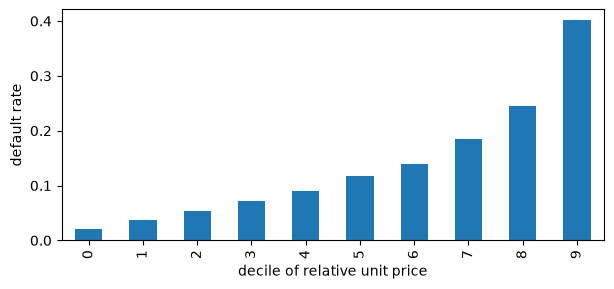

In [12]:
t = f[f.target.notna()]
dec = pd.qcut(t.ec_price_rel, 10, labels=False)
ax = t.groupby(dec).target.mean().plot(kind="bar", figsize=(7, 3))
ax.set_xlabel("decile of relative unit price")
ax.set_ylabel("default rate")
plt.show()

## Validation

Stratified K fold CV on the training applications, with K set by `N_FOLDS`. AUC is tracked next to KS because it is a smoother guide for model selection.

Profile fields, application timing and a few ecommerce share blocks add noise for the boosted trees, so a second feature set drops them. Training on both sets gives the blend some diversity.

In [13]:
tr = f[f.target.notna()].reset_index(drop=True)
te = f[f.target.isna()].reset_index(drop=True)
ids = ["application_id", "customer_id", "target"]
X_all, X_test_all = tr.drop(columns=ids), te.drop(columns=ids)
y = tr.target.astype(int).values

noise = ["region", "employment_type", "housing_status", "age", "employment_tenure_months", "dependents",
         "tenure_to_age", "income_per_dependent", "loan_purpose", "decision_lag_h", "app_hour", "app_dow"]
noise += [c for c in X_all.columns if c.startswith(("ec_share_", "ec_catqty_", "cs_shift", "buh_"))]
sets = {"full": list(X_all.columns), "lean": [c for c in X_all.columns if c not in noise]}

folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_all, y))
app = load_apps()
M, E = factor_inputs(app)
pos = pd.Series(np.arange(len(app)), index=app.application_id)
p_tr, p_te = pos[tr.application_id].values, pos[te.application_id].values
fac = [factor_features(M, E, app.target.values, p_tr[a]) for a, b in folds]
frame = lambda k: (pd.concat([X_all, fac[k].iloc[p_tr].reset_index(drop=True)], axis=1),
                   pd.concat([X_test_all, fac[k].iloc[p_te].reset_index(drop=True)], axis=1))
sets = {k: v + list(fac[0].columns) for k, v in sets.items()}
ks = lambda p: ks_2samp(p[y == 1], p[y == 0]).statistic
rank = lambda v: rankdata(v) / len(v)
report = lambda name, p: print(f"{name:12s} auc {roc_auc_score(y, p):.5f}  ks {ks(p):.5f}")

## Models

In [14]:
def fit_lgb(cols, tag, seed):
    params = dict(objective="binary", learning_rate=LR, num_leaves=15, min_child_samples=200,
                  feature_fraction=0.3, bagging_fraction=0.8, bagging_freq=1, lambda_l2=20, max_bin=127,
                  seed=seed, deterministic=True, force_row_wise=True, n_jobs=-1, verbose=-1)
    oof, pred = np.zeros(len(X_all)), np.zeros(len(X_test_all))
    for k, (a, b) in enumerate(folds):
        X, Xt = [d[cols[k]] for d in frame(k)]
        m = lgb.train(params, lgb.Dataset(X.iloc[a], y[a]), 20000, valid_sets=[lgb.Dataset(X.iloc[b], y[b])],
                      callbacks=[lgb.early_stopping(300, verbose=False)])
        m.save_model(f"models/lgb_{tag}_s{seed}_f{k}.txt")
        oof[b] = m.predict(X.iloc[b])
        pred += m.predict(Xt) / len(folds)
    return oof, pred


def fit_cat(cols, tag, seed):
    oof, pred = np.zeros(len(X_all)), np.zeros(len(X_test_all))
    for k, (a, b) in enumerate(folds):
        X, Xt = [d[cols[k]].copy() for d in frame(k)]
        cats = [c for c in X.columns if str(X[c].dtype) == "category"]
        X[cats], Xt[cats] = X[cats].astype(str), Xt[cats].astype(str)
        m = CatBoostClassifier(iterations=int(60 / LR), learning_rate=3 * LR, depth=6, l2_leaf_reg=5, eval_metric="AUC",
                               od_type="Iter", od_wait=300, random_seed=seed, cat_features=cats, verbose=0)
        m.fit(X.iloc[a], y[a], eval_set=(X.iloc[b], y[b]))
        m.save_model(f"models/cat_{tag}_s{seed}_f{k}.cbm")
        oof[b] = m.predict_proba(X.iloc[b])[:, 1]
        pred += m.predict_proba(Xt)[:, 1] / len(folds)
    return oof, pred


def fit_xgb(cols, tag, seed):
    oof, pred = np.zeros(len(X_all)), np.zeros(len(X_test_all))
    for k, (a, b) in enumerate(folds):
        X, Xt = [d[cols[k]] for d in frame(k)]
        m = xgb.XGBClassifier(n_estimators=10000, learning_rate=LR, max_depth=4, min_child_weight=20,
                              subsample=0.8, colsample_bytree=0.3, reg_lambda=20, tree_method="hist", max_bin=128,
                              enable_categorical=True, eval_metric="auc", early_stopping_rounds=300,
                              random_state=seed, n_jobs=-1)
        m.fit(X.iloc[a], y[a], eval_set=[(X.iloc[b], y[b])], verbose=False)
        m.save_model(f"models/xgb_{tag}_s{seed}_f{k}.json")
        oof[b] = m.predict_proba(X.iloc[b])[:, 1]
        pred += m.predict_proba(Xt)[:, 1] / len(folds)
    return oof, pred


def fit_set(cols, tag):
    for s in range(3):
        res[f"lgb_{tag}_{s}"] = fit_lgb(cols, tag, s)
    for s in range(TREE_SEEDS):
        res[f"cat_{tag}_{s}"] = fit_cat(cols, tag, s)
        res[f"xgb_{tag}_{s}"] = fit_xgb(cols, tag, s)

The spline logistic regression sees each numeric feature through a smooth curve. It reaches an AUC close to the trees on its own, which suggests the risk is largely additive, and it brings a different error pattern to the blend.

In [15]:
num = [c for c in sets["lean"] if str(frame(0)[0][c].dtype) != "category"]
flag = [c for c in num if frame(0)[0][c].isna().mean() > 0.01]


def linear_matrix(X, med):
    return pd.concat([X[num].astype(float).fillna(med), X[flag].isna().astype(float).add_suffix("_na")], axis=1)


def fit_linear():
    oof, pred = np.zeros(len(X_all)), np.zeros(len(X_test_all))
    for k, (a, b) in enumerate(folds):
        X, Xt = frame(k)
        med = X.iloc[a][num].median()
        m = make_pipeline(QuantileTransformer(n_quantiles=200, subsample=10**6, random_state=SEED),
                          SplineTransformer(n_knots=4, degree=2), LogisticRegression(C=0.03, max_iter=3000))
        m.fit(linear_matrix(X.iloc[a], med), y[a])
        joblib.dump((m, med), f"models/linear_f{k}.pkl")
        oof[b] = m.predict_proba(linear_matrix(X.iloc[b], med))[:, 1]
        pred += m.predict_proba(linear_matrix(Xt, med))[:, 1] / len(folds)
    return oof, pred

In [16]:
res = {}
for tag, cols in sets.items():
    fit_set([cols] * len(folds), tag)
res["linear"] = fit_linear()

Many features are close copies of each other, so a third set keeps only the 80 strongest. The ranking for each fold uses the gain of that fold's lean LightGBM models only, which keeps the validation rows out of the selection.

In [17]:
top = []
for k in range(len(folds)):
    gain = sum(lgb.Booster(model_file=f"models/lgb_lean_s{s}_f{k}.txt").feature_importance("gain") for s in range(3))
    top.append(list(pd.Series(gain, index=sets["lean"]).sort_values(ascending=False).index[:80]))
fit_set(top, "top")
for name, (oof, _) in res.items():
    report(name, oof)

lgb_full_0   auc 0.84683  ks 0.52473
lgb_full_1   auc 0.84683  ks 0.52537
lgb_full_2   auc 0.84672  ks 0.52381
cat_full_0   auc 0.84581  ks 0.52290
xgb_full_0   auc 0.84685  ks 0.52582
lgb_lean_0   auc 0.84667  ks 0.52490
lgb_lean_1   auc 0.84659  ks 0.52444
lgb_lean_2   auc 0.84678  ks 0.52469
cat_lean_0   auc 0.84566  ks 0.52353
xgb_lean_0   auc 0.84677  ks 0.52457
linear       auc 0.84446  ks 0.52222
lgb_top_0    auc 0.84626  ks 0.52542


lgb_top_1    auc 0.84653  ks 0.52779
lgb_top_2    auc 0.84651  ks 0.52753
cat_top_0    auc 0.84514  ks 0.52306
xgb_top_0    auc 0.84659  ks 0.52737


## Blend

Within each feature set the seeds of each model are averaged first, then LightGBM, CatBoost and XGBoost get equal weight. In the main blend CatBoost gets one extra share because it was the most stable model across folds, and the linear model takes 20 percent.

The other variants mix the same models with different weights. Their CV scores are nearly identical, and `VARIANT` picks the one written as the submission.

In [18]:
def avg(model, tag, i, n):
    return np.mean([rank(res[f"{model}_{tag}_{s}"][i]) for s in range(n)], axis=0)


def trees(tag, i):
    return (avg("lgb", tag, i, 3) + avg("cat", tag, i, TREE_SEEDS) + avg("xgb", tag, i, TREE_SEEDS)) / 3


def core(i):
    return (trees("full", i) + trees("lean", i) + avg("cat", "full", i, TREE_SEEDS) + avg("cat", "lean", i, TREE_SEEDS)) / 4


lin = lambda i: rank(res["linear"][i])
variants = {
    "main": lambda i: 0.8 * core(i) + 0.2 * lin(i),
    "top_mix": lambda i: 0.8 * (core(i) + trees("top", i)) / 2 + 0.2 * lin(i),
    "top_heavy": lambda i: 0.8 * (core(i) + 2 * trees("top", i)) / 3 + 0.2 * lin(i),
    "top_only": lambda i: 0.8 * trees("top", i) + 0.2 * lin(i),
    "trees_only": lambda i: (core(i) + trees("top", i)) / 2,
    "linear30": lambda i: 0.7 * (core(i) + trees("top", i)) / 2 + 0.3 * lin(i),
}
for name, blend in variants.items():
    report(name, blend(0))
    pd.DataFrame({"application_id": te.application_id, "default_probability": blend(1)}).to_csv(f"variants/{name}.csv", index=False)
pd.to_pickle(res, "models/predictions.pkl")

main         auc 0.84738  ks 0.52674


top_mix      auc 0.84754  ks 0.52725


top_heavy    auc 0.84750  ks 0.52794


top_only     auc 0.84726  ks 0.52831


trees_only   auc 0.84724  ks 0.52696


linear30     auc 0.84753  ks 0.52715


In [19]:
sub = pd.DataFrame({"application_id": te.application_id, "default_probability": variants[VARIANT](1)})
assert len(sub) == 30000 and sub.application_id.is_unique and sub.default_probability.between(0, 1).all()
sub.to_csv("DSC0152_kali ini beneran deh_Submisi.csv", index=False)
sub.head()

,application_id,default_probability
0,A_779e4e5a0ca90902,0.223662
1,A_289cbaf13ec58feb,0.656753
2,A_172169d79a3f4a35,0.278756
3,A_51ff46a3e1427786,0.973896
4,A_bd7e505dcbebaf89,0.786727
